# 제11장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch11


## 11.11 합성 영상의 필터·풀링과 크기 계산

고정 필터의 국소 연산과 활성화·풀링을 배열 수준에서 확인한다.

첫 그림은 원 영상, 두 번째는 부호가 있는 응답, 세 번째는 ReLU 뒤 최대 풀링이다. 각 패널의 색 범위가 달라 색 농도를 직접 비교하지 않는다.

주의: 학습된 CNN이나 영상 분류 성능 실험이 아니다. 커널을 뒤집지 않는 상관 연산이며 단일 채널·단일 필터만 다룬다.

In [2]:
%run sec_11_convolution.py

{
  "input_shape": [
    12,
    12
  ],
  "feature_shape": [
    10,
    10
  ],
  "pooled_shape": [
    5,
    5
  ],
  "kernel": [
    [
      -1.0,
      0.0,
      1.0
    ],
    [
      -2.0,
      0.0,
      2.0
    ],
    [
      -1.0,
      0.0,
      1.0
    ]
  ],
  "stride": 1,
  "padding": 0
}


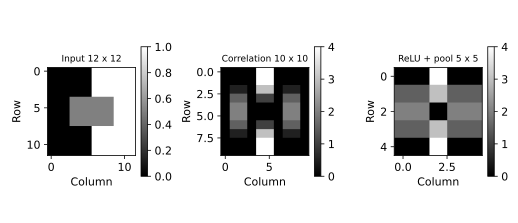

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/convolution.svg"))

### 확인 과제

(12−3)/1+1=10과 풀링 10/2=5를 실제 shape와 대조하고 커널 부호를 바꾸었을 때 응답 방향을 설명한다.

## 11.12 시간순 분할의 한 단계 예측과 지속성 기준선

과거 12개 값으로 다음 한 값을 예측하고 아무 학습도 하지 않는 지속성 예측과 비교한다.

테스트 각 시점에서 직전 실제 관측이 사용 가능한 한 단계 rolling 예측이다. 고정 시점에서 미래 전체를 한 번에 내다본 다단계 예측이 아니다.

주의: Ridge 기준선 예제이며 LSTM 성능이라고 부르지 않는다. 중첩 윈도는 경계의 과거 관측을 공유하지만 미래 목표를 훈련에 넣지는 않는다.

In [4]:
%run sec_12_timeseries_forecast.py

{
  "train_windows": 261,
  "test_windows": 87,
  "metrics": {
    "ridge": {
      "RMSE": 0.17834284419927388,
      "MAE": 0.15006759504095918
    },
    "persistence": {
      "RMSE": 0.2624706632413813,
      "MAE": 0.20958071257908045
    }
  }
}


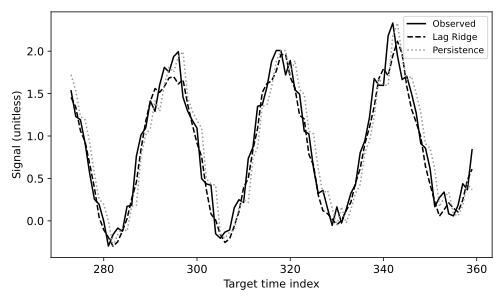

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/timeseries_forecast.svg"))

### 확인 과제

각 X 행의 마지막 시간보다 y의 시간이 1 크다는 것을 확인하고, lag를 1·12·24로 바꾸어 비교한다.